# Unidades de Saúde

A camada “Unidades de Saúde”, disponibilizada no portal Salvador Dados, informa a FMLF como responsável e apresenta criação e publicação em 07/04/2021. Não foi identificada uma data de atualização dos registros. Após padronização das categorias, foram selecionados 142 registros de UBS/USF: 45 UBS e 97 USF, dos quais 15 estão em Centro/Brotas. A análise inicial medirá proximidade às unidades cadastradas nessa camada, sem confirmar funcionamento atual ou capacidade de atendimento. A combinação com a população do Censo 2022 apresenta uma limitação temporal.

In [58]:
from pathlib import Path
import geopandas as gpd
import matplotlib.pyplot as plt

caminho = Path("../dados/brutos/saude/saude.gpkg")
print(Path.exists(caminho))
unid_saude = gpd.read_file(caminho)
unid_saude.head()

True


/home/emanu/projetos/ftl-projeto-final/.venv/lib/python3.10/site-packages/pyogrio/geopandas.py:382: UserWarning: More than one layer found in 'saude.gpkg': 'sau_p' (default), 'layer_styles'. Specify layer parameter to avoid this warning.
  result = read_func(


,tipo,tipo_1,unidade,logradouro,numero,complement,bairro,cod_cep,x,y,geometry
0,2.0,USF,USF DO ALTO DAS POMBAS,RUA NOSSA SENHORA DE FATIMA,S/N,ALTO DAS POMBAS,ALTO DAS POMBAS,40226500,552650.623,8562614.586,POINT (552650.623 8562614.586)
1,3.0,USF,USF PROFESSOR SABINO SILVA,RUA REINALDO DE MATOS,S/N,None,NORDESTE DE AMARALINA,40100000,557239.402,8561790.051,POINT (557239.402 8561790.051)
2,4.0,USF,USF MENINO JOEL,RUA AVANY ARGOLO,S/N,None,NORDESTE DE AMARALINA,41905785,557209.288,8561753.862,POINT (557209.288 8561753.862)
3,5.0,CAPS,CAPS II OSWALDO CAMARGO,RUA ITABUNA,02,None,RIO VERMELHO,41940650,555099.827,8561925.487,POINT (555099.827 8561925.487)
4,6.0,MULT,MULTICENTRO DE SAUDE AMARALINA DR ADRIANO PONDE,RUA VISCONDE DE ITAB0RAI,1192,None,AMARALINA,41900000,557628.950,8561453.320,POINT (557628.95 8561453.32)


In [59]:
print("Dimensões:", unid_saude.shape)
print("Colunas:", unid_saude.columns.to_frame())
print("Sistema de Coordenadas:", unid_saude.crs)
print("Tipo de Geometria:", unid_saude.geometry.geom_type.value_counts())
print("Sistema de Coordenadas:", unid_saude.crs)

Dimensões: (234, 11)
Colunas:                      0
tipo              tipo
tipo_1          tipo_1
unidade        unidade
logradouro  logradouro
numero          numero
complement  complement
bairro          bairro
cod_cep        cod_cep
x                    x
y                    y
geometry      geometry
Sistema de Coordenadas: EPSG:31984
Tipo de Geometria: Point    234
Name: count, dtype: int64
Sistema de Coordenadas: EPSG:31984


In [60]:
print(unid_saude["tipo_1"].unique())


['USF' 'CAPS' 'MULT' 'UBS' 'CEO' 'UPA' 'CSM' 'DISTRITO' 'PA' 'SAMU'
 'SESAB' 'UAO' 'HMS' 'SAE' 'SEDE' 'RT' 'UDM' 'USB' 'SSF' 'CEREST' 'SAMU\n'
 'OUTRO\n' 'UPA\n' 'USF\n']


In [61]:
unid_saude["tipo_tratado"] = (
    unid_saude["tipo_1"].astype("string").str.strip().str.upper()
)

print(unid_saude["tipo_tratado"].value_counts(dropna=False))

tipo_tratado
USF         97
UBS         45
CAPS        17
SAMU        13
DISTRITO    12
UPA          7
SEDE         7
PA           6
CEO          6
MULT         4
CSM          3
SAE          3
RT           3
SESAB        2
UAO          2
USB          2
HMS          1
UDM          1
SSF          1
CEREST       1
OUTRO        1
Name: count, dtype: Int64


In [65]:
ubs_usf = unid_saude.loc[
    unid_saude["tipo_tratado"].isin(["UBS", "USF"])
].copy()

print(ubs_usf["tipo_tratado"].value_counts())
print("TOtal de UBS/USF:", len(ubs_usf))

tipo_tratado
USF    97
UBS    45
Name: count, dtype: Int64
TOtal de UBS/USF: 142


In [71]:
print("Nomes ausentes:", ubs_usf["unidade"].isna().sum())
print("Nomes duplicados:", ubs_usf["unidade"].duplicated().sum())

print("Geometria ausente:", ubs_usf.geometry.isna().sum())
print("Geometria vazia:", ubs_usf.geometry.is_empty.sum())
print("Geometrias inválidas:", (~ubs_usf.geometry.is_valid).sum())

print("Geometrias repetidas:", ubs_usf.geometry.duplicated().sum())

Nomes ausentes: 0
Nomes duplicados: 0
Geometria ausente: 0
Geometria vazia: 0
Geometrias inválidas: 0
Geometrias repetidas: 0


In [85]:
caminho_pref = Path("../dados/brutos/bairros/prefeitura_bairro.gpkg")
print(Path.exists(caminho_pref))
pref_bairro = gpd.read_file(caminho_pref)
pref_bairro.head()

True


/home/emanu/projetos/ftl-projeto-final/.venv/lib/python3.10/site-packages/pyogrio/geopandas.py:382: UserWarning: More than one layer found in 'prefeitura_bairro.gpkg': 'prefeituras_bairro_a' (default), 'layer_styles'. Specify layer parameter to avoid this warning.
  result = read_func(


,PREF_BAIRR,COD_PBR,ID,QTD_BAIRRO,area,geometry
0,Prefeitura-bairro IV - Itapuã / Ipitanga,IV,4,17,94380440.97,"MULTIPOLYGON (((563183.372 8565464.348, 563137..."
1,Prefeitura-bairro X - Valéria,X,10,4,25325166.31,"MULTIPOLYGON (((560318.999 8574966.432, 560166..."
2,Prefeitura-bairro V - Cidade Baixa,V,5,14,8132459.00,"MULTIPOLYGON (((553769.31 8569249.552, 553767...."
3,Prefeitura-bairro III - Cajazeiras,III,3,17,22160586.15,"MULTIPOLYGON (((566822.94 8573201.26, 566811.8..."
4,Prefeitura-bairro IX - Pau da Lima,IX,9,13,19905726.69,"MULTIPOLYGON (((563789.494 8569538.91, 563559...."


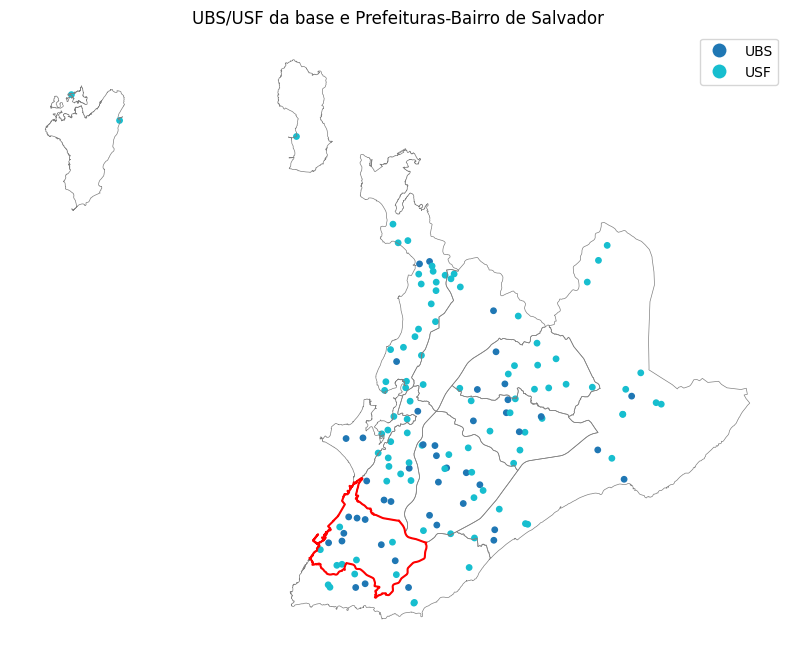

In [87]:
piloto = pref_bairro.loc[
    pref_bairro["COD_PBR"] == "I"
].copy()

fig, ax = plt.subplots(figsize=(10, 10))

pref_bairro.boundary.plot(
    ax=ax, color="gray", linewidth=0.5
)

piloto.boundary.plot(
    ax=ax, color="red", linewidth=1.5
)

ubs_usf.plot(
    ax=ax,
    column="tipo_tratado",
    categorical=True,
    legend=True,
    markersize=15
)

ax.set_title("UBS/USF da base e Prefeituras-Bairro de Salvador")
ax.set_axis_off()

plt.show()

In [88]:
limite_piloto = piloto.geometry.iloc[0]

unidades_no_piloto = ubs_usf.loc[
    ubs_usf.geometry.intersects(limite_piloto)
].copy()

print(
    unidades_no_piloto["tipo_tratado"]
    .value_counts()
)

print("Total no piloto:", len(unidades_no_piloto))

tipo_tratado
UBS    8
USF    7
Name: count, dtype: Int64
Total no piloto: 15


In [89]:
print(
    unidades_no_piloto[
        ["tipo_tratado", "unidade", "bairro"]
    ]
    .sort_values(["tipo_tratado", "unidade"])
    .to_string(index=False)
)

tipo_tratado                                       unidade                  bairro
         UBS            UBS 19H CENTRO DE SAUDE PELOURINHO                  NAZARÉ
         UBS                              UBS CARLOS GOMES           DOIS DE JULHO
         UBS    UBS DR PERICLES ESTEVES CARDOSO - BARBALHO                BARBALHO
         UBS                     UBS MAJOR COSME DE FARIAS         COSME DE FARIAS
         UBS                           UBS MANOEL VITORINO                  BROTAS
         UBS                         UBS PROF MARIO ANDREA                MACAÚBAS
         UBS                         UBS RAMIRO DE AZEVEDO                  NAZARÉ
         UBS                             UBS SANTO ANTONIO           SANTO ANTÔNIO
         USF UNIDADE DE SAUDE DA FAMILIA TERREIRO DE JESUS        CENTRO HISTÓRICO
         USF                           USF CANDEAL PEQUENO                 CANDEAL
         USF                          USF CLEMENTINO FRAGA                  GARCIA
    

In [90]:
territorio_salvador = pref_bairro.geometry.union_all()

unidades_fora = ubs_usf.loc[
    ~ubs_usf.geometry.intersects(territorio_salvador)
].copy()

print("Unidades fora do território:", len(unidades_fora))

print(
    unidades_fora[["tipo_tratado", "unidade", "bairro"]]
    .to_string(index=False)
)

Unidades fora do território: 0
Empty DataFrame
Columns: [tipo_tratado, unidade, bairro]
Index: []


In [91]:
pasta_saida = Path("../dados/processados")
pasta_saida.mkdir(parents=True, exist_ok=True)

arquivo_saude = pasta_saida / "ubs_usf_salvador.gpkg"

ubs_usf.to_file(
    arquivo_saude,
    layer="ubs_usf",
    driver="GPKG",
    index=False
)

In [92]:
conferencia_saude = gpd.read_file(
    arquivo_saude,
    layer="ubs_usf"
)

print("Registros:", len(conferencia_saude))
print("CRS:", conferencia_saude.crs)
print(conferencia_saude["tipo_tratado"].value_counts())

Registros: 142
CRS: EPSG:31984
tipo_tratado
USF    97
UBS    45
Name: count, dtype: int64
